**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053 - Ciencia y analítica de datos**

Tecnológico de Monterrey

Prof Grettel Barceló Alonso

**Semana 5**
Preprocesamiento de datos

---

*   NOMBRE: Carlos Joel Bugarín González
*   MATRÍCULA: A01841627

En esta actividad trabajarás con el archivo `heart_disease.csv`, basado en un conjunto de datos sobre pacientes y variables clínicas relacionadas con enfermedades cardíacas, disponible en Kaggle.

Los datos fueron recopilados para analizar la presencia de enfermedades cardíacas en los pacientes y contienen información demográfica, clínica y resultados de pruebas diagnósticas. Los indicadores incluidos son:

* `id`: Identificador único de cada paciente
* `age`: Edad del paciente en años
* `origin`: Lugar de estudio
* `sex`: Masculino / Femenino
* `cp`: Tipo de dolor torácico (angina típica, angina atípica, no anginal, asintomático)
* `trestbps`: Presión arterial en reposo (en mm Hg al ingreso al hospital)
* `chol`: Colesterol sérico en mg/dl
* `fbs`: Si el azúcar en ayunas > 120 mg/dl
* `restecg`: Resultados del electrocardiograma en reposo (normal, anomalía ST-T, hipertrofia ventricular izquierda)
* `thalach`: Frecuencia cardíaca máxima alcanzada
* `exang`: Angina inducida por ejercicio (Verdadero / Falso)
* `oldpeak`: Depresión del segmento ST inducida por ejercicio respecto al reposo
* `slope`: Pendiente del segmento ST en el pico de ejercicio
* `ca`: Número de vasos principales coloreados por fluoroscopía (0 - 3)
* `thal`: Resultado de la prueba de perfusión cardíaca (normal, defecto fijo, defecto reversible)
* `num`: Indica si el paciente tiene o no enfermedad cardíaca, o el grado de enfermedad (0 = sano, 1 - 4 = enfermedad) Es la variable de salida o *target*, es decir, la que se pretende predecir más adelante al construir el modelo.

**NOTA IMPORTANTE:** Asegúrate de responder *explícitamente* todos los cuestionamientos.

In [7]:
# Importar las bibliotecas necesarias
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.impute import SimpleImputer

1. Descarga el archivo: `heart_disease.csv` y guarda, en un dataframe (`cardio_df`), todos sus registros.
* Haz que la columna `id` sea el índice del dataframe.
* Utiliza el método `info()` del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto?
* Determina la cantidad de valores únicos por columna.

In [12]:
from google.colab import files

archivos_subidos = files.upload()

Saving heart_disease.csv to heart_disease (1).csv


In [13]:
# Cargar todos los registros y establecer id como índice
cardio_df = pd.read_csv("heart_disease.csv", index_col="id")

# Mostrar las dimensiones y las primeras filas
display(
    pd.Series({
        "Número de registros": cardio_df.shape[0],
        "Número de columnas": cardio_df.shape[1]
    }).to_frame(name="Cantidad")
)

display(cardio_df.head())

# Obtener el resumen de tipos de datos y valores no nulos
cardio_df.info()

# Contar las columnas numéricas y las de tipo object o string
display(
    pd.Series({
        "Columnas numéricas":
            cardio_df.select_dtypes(include="number").shape[1],
        "Columnas de tipo object o string":
            cardio_df.select_dtypes(include=["object", "string"]).shape[1]
    }).to_frame(name="Cantidad")
)

# Contar los valores únicos por columna, sin incluir los faltantes
display(
    cardio_df.nunique(dropna=True).to_frame(name="Valores únicos")
)

,Cantidad
Número de registros,918
Número de columnas,15


,age,sex,origin,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
id,,,,,,,,,,,,,,,
1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


<class 'pandas.core.frame.DataFrame'>
Index: 918 entries, 1 to 920
Data columns (total 15 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       918 non-null    int64  
 1   sex       918 non-null    object 
 2   origin    918 non-null    object 
 3   cp        918 non-null    object 
 4   trestbps  859 non-null    float64
 5   chol      888 non-null    float64
 6   fbs       829 non-null    object 
 7   restecg   918 non-null    object 
 8   thalch    863 non-null    float64
 9   exang     863 non-null    object 
 10  oldpeak   856 non-null    float64
 11  slope     610 non-null    object 
 12  ca        309 non-null    float64
 13  thal      434 non-null    object 
 14  num       918 non-null    int64  
dtypes: float64(5), int64(2), object(8)
memory usage: 114.8+ KB


,Cantidad
Columnas numéricas,7
Columnas de tipo object o string,8


,Valores únicos
age,50
sex,2
origin,4
cp,4
trestbps,60
chol,216
fbs,2
restecg,3
thalch,119
exang,2


**Resultados del ejercicio 1**

Se cargó el archivo completo en el dataframe `cardio_df` y se estableció la columna `id` como índice. El dataframe contiene 918 registros y 15 columnas, sin contar el índice.

El resumen obtenido con `info()` muestra 7 columnas numéricas: 2 de tipo `int64` y 5 de tipo `float64`. Las otras 8 columnas tienen tipo `object`. Aunque la pregunta las agrupa como columnas de texto, este tipo también puede almacenar otros valores; en particular, `fbs` y `exang` contienen valores booleanos y datos faltantes.

La cantidad de valores únicos se obtuvo con `nunique()`, sin incluir los valores faltantes. Estos resultados permiten identificar las variables con pocas categorías y sirven como punto de partida para revisar su clasificación en el ejercicio 2.

2. Examina las variables numéricas que presentan pocos valores únicos, ya que esto puede indicar que en realidad se tratan de variables categóricas codificadas como números.
* Si existen casos de este tipo, conviértelas a categóricas. Antes de hacerlo, revisa sus descripciones para determinar si son ordinales o nominales y, si son ordinales, establece el orden correcto de las categorías.

In [14]:
# Revisar la cantidad de valores únicos de las variables numéricas
display(
    cardio_df.select_dtypes(include="number")
    .nunique()
    .sort_values()
    .to_frame(name="Valores únicos")
)

# Representar ca como categórica ordinal
cardio_df["ca"] = pd.Categorical(
    cardio_df["ca"],
    categories=[0, 1, 2, 3],
    ordered=True
)

# Representar num como categórica ordinal
cardio_df["num"] = pd.Categorical(
    cardio_df["num"],
    categories=[0, 1, 2, 3, 4],
    ordered=True
)

# Verificar el tipo, las categorías, el orden y los faltantes
resumen_categoricas = pd.DataFrame({
    "Tipo": cardio_df[["ca", "num"]].dtypes.astype(str),
    "Categorías": [
        cardio_df["ca"].cat.categories.tolist(),
        cardio_df["num"].cat.categories.tolist()
    ],
    "Ordenadas": [
        cardio_df["ca"].cat.ordered,
        cardio_df["num"].cat.ordered
    ],
    "Faltantes": cardio_df[["ca", "num"]].isna().sum()
})

display(resumen_categoricas)

# Comprobar los tipos del dataframe después de la conversión
cardio_df.info()

,Valores únicos
ca,4
num,5
age,50
oldpeak,53
trestbps,60
thalch,119
chol,216


,Tipo,Categorías,Ordenadas,Faltantes
ca,category,"[0, 1, 2, 3]",True,609
num,category,"[0, 1, 2, 3, 4]",True,0


<class 'pandas.core.frame.DataFrame'>
Index: 918 entries, 1 to 920
Data columns (total 15 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   age       918 non-null    int64   
 1   sex       918 non-null    object  
 2   origin    918 non-null    object  
 3   cp        918 non-null    object  
 4   trestbps  859 non-null    float64 
 5   chol      888 non-null    float64 
 6   fbs       829 non-null    object  
 7   restecg   918 non-null    object  
 8   thalch    863 non-null    float64 
 9   exang     863 non-null    object  
 10  oldpeak   856 non-null    float64 
 11  slope     610 non-null    object  
 12  ca        309 non-null    category
 13  thal      434 non-null    object  
 14  num       918 non-null    category
dtypes: category(2), float64(4), int64(1), object(8)
memory usage: 102.6+ KB


**Resultados del ejercicio 2**

Al revisar las variables numéricas, se identificaron `ca` y `num` como candidatas a una representación categórica, ya que presentan cuatro y cinco valores únicos, respectivamente. La decisión se tomó considerando sus descripciones, además de su cantidad de valores distintos.

La variable `ca` representa un conteo de vasos principales coloreados por fluoroscopía. Para esta actividad se representó como categórica ordinal, con el orden `0 < 1 < 2 < 3`, porque sus categorías corresponden a cantidades crecientes. Aunque también puede analizarse como un conteo numérico, aquí se eligió hacer explícitos esos niveles.

La variable `num` se convirtió en categórica ordinal con el orden `0 < 1 < 2 < 3 < 4`, siguiendo la descripción de la consigna sobre ausencia y grados de enfermedad. Este orden no supone que exista una distancia clínica uniforme entre las categorías.

Las demás variables numéricas se conservaron como tales porque representan mediciones o cantidades. Después de la conversión, el dataframe mantiene sus 918 registros y 15 columnas, y los valores faltantes de `ca` permanecen sin modificación.

3. Obtén las estadísticas descriptivas de las variables, realizando el análisis por separado para las variables numéricas y las categóricas.
* Para las numéricas, incluye el sesgo y la curtosis.
* Para las categóricas, imprime además las tablas de frecuencia.

In [15]:
# Separar las variables numéricas y las categóricas
variables_numericas = cardio_df.select_dtypes(include="number")

variables_categoricas = cardio_df.select_dtypes(
    include=["object", "string", "category", "bool"]
)

# Estadísticas descriptivas de las variables numéricas
resumen_numericas = variables_numericas.describe().T

# Agregar sesgo y exceso de curtosis
resumen_numericas["Sesgo"] = variables_numericas.skew()
resumen_numericas["Exceso de curtosis"] = variables_numericas.kurt()

display(resumen_numericas.round(3))

# Estadísticas descriptivas de las variables categóricas
resumen_categoricas = variables_categoricas.describe().T

resumen_categoricas = resumen_categoricas.rename(columns={
    "count": "Valores observados",
    "unique": "Categorías observadas",
    "top": "Moda",
    "freq": "Frecuencia de la moda"
})

display(resumen_categoricas)

# Tablas de frecuencia de cada variable categórica
# Se incluyen los faltantes y el porcentaje sobre los 918 registros
for columna in variables_categoricas.columns:
    tabla_frecuencias = (
        variables_categoricas[columna]
        .value_counts(dropna=False, sort=False)
        .to_frame(name="Frecuencia")
    )

    tabla_frecuencias["Porcentaje del total (%)"] = (
        tabla_frecuencias["Frecuencia"] / len(cardio_df) * 100
    )

    tabla_frecuencias.index.name = columna

    display(tabla_frecuencias.round(2))

,count,mean,std,min,25%,50%,75%,max,Sesgo,Exceso de curtosis
age,918.0,53.531,9.413,28.0,47.0,54.0,60.0,77.0,-0.194,-0.383
trestbps,859.0,132.295,18.536,80.0,120.0,130.0,140.0,200.0,0.630,0.633
chol,888.0,242.189,53.425,85.0,216.0,223.0,268.0,603.0,1.641,6.574
thalch,863.0,137.528,25.950,60.0,120.0,140.0,157.0,202.0,-0.209,-0.484
oldpeak,856.0,0.881,1.092,-2.6,0.0,0.5,1.5,6.2,1.038,1.120


,Valores observados,Categorías observadas,Moda,Frecuencia de la moda
sex,918,2,Male,724
origin,918,4,Cleveland,304
cp,918,4,asymptomatic,495
fbs,829,2,False,691
restecg,918,3,normal,551
exang,863,2,False,526
slope,610,3,flat,345
ca,309,4,0,181
thal,434,3,normal,196
num,918,5,0,411


,Frecuencia,Porcentaje del total (%)
sex,,
Male,724,78.87
Female,194,21.13


,Frecuencia,Porcentaje del total (%)
origin,,
Cleveland,304,33.12
Hungary,292,31.81
Switzerland,122,13.29
VA Long Beach,200,21.79


,Frecuencia,Porcentaje del total (%)
cp,,
typical angina,45,4.90
asymptomatic,495,53.92
non-anginal,204,22.22
atypical angina,174,18.95


...

,Frecuencia,Porcentaje del total (%)
exang,,
False,526,57.30
True,337,36.71
NaN,55,5.99


,Frecuencia,Porcentaje del total (%)
slope,,
downsloping,63,6.86
flat,345,37.58
upsloping,202,22.00
NaN,308,33.55


,Frecuencia,Porcentaje del total (%)
ca,,
0,181,19.72
1,67,7.30
2,41,4.47
3,20,2.18
NaN,609,66.34


,Frecuencia,Porcentaje del total (%)
thal,,
fixed defect,46,5.01
normal,196,21.35
reversable defect,192,20.92
NaN,484,52.72


,Frecuencia,Porcentaje del total (%)
num,,
0,411,44.77
1,263,28.65
2,109,11.87
3,107,11.66
4,28,3.05


**Resultados del ejercicio 3**

Se analizaron por separado las cinco variables numéricas y las diez variables categóricas. Para las numéricas se obtuvieron el número de observaciones, la media, la desviación estándar, los valores mínimo y máximo, los cuartiles, el sesgo y el exceso de curtosis.

La edad presenta una media de 53.53 años y una mediana de 54, con una ligera asimetría negativa. La frecuencia cardíaca máxima (`thalch`) también muestra una asimetría negativa pequeña. Estos indicadores describen sus distribuciones, pero no son suficientes para afirmar que siguen una distribución normal.

La presión arterial en reposo (`trestbps`) presenta asimetría positiva. El colesterol (`chol`) muestra una asimetría positiva más marcada, con una media de 242.19 mg/dl y una mediana de 223 mg/dl. Su exceso de curtosis de 6.57 indica colas más pesadas respecto a la referencia normal y justifica revisar sus valores extremos en los ejercicios posteriores. Por su parte, `oldpeak` también presenta asimetría positiva, con una media de 0.88 y una mediana de 0.50.

Para las variables categóricas se identificaron la cantidad de valores observados, el número de categorías, la moda y su frecuencia. Entre las categorías más frecuentes se encuentran `Male` en `sex`, `Cleveland` en `origin`, `asymptomatic` en `cp` y `normal` en `restecg`. En la variable objetivo `num`, la categoría más frecuente es 0, con 411 registros.

Las tablas de frecuencia incluyen los valores faltantes y calculan los porcentajes sobre el total de 918 registros. En cambio, los estadísticos descriptivos se calculan con los valores observados de cada variable. Por ello, los tamaños utilizados difieren entre columnas y los resultados deben interpretarse considerando los datos disponibles.

4. Calcula el porcentaje de valores faltantes en cada columna.
* Elimina aquellas columnas cuyo porcentaje de valores faltantes supere el 30%.
* Crea un mapa de calor que visualice la distribución de los valores faltantes en todas las columnas restantes.
* Algunas variables presentan valores faltantes de manera simultánea; es decir, en el mapa se pueden identificar filas donde varias están ausentes al mismo tiempo. Enumera cuáles son dichas variables e investiga si esta concurrencia tiene sentido desde un punto de vista médico o clínico.

,Faltantes,Porcentaje (%)
ca,609,66.34
thal,484,52.72
slope,308,33.55
fbs,89,9.69
oldpeak,62,6.75
trestbps,59,6.43
thalch,55,5.99
exang,55,5.99
chol,30,3.27
sex,0,0.00


,Faltantes,Porcentaje (%)
ca,609,66.34
thal,484,52.72
slope,308,33.55


,Cantidad
Registros restantes,918
Columnas restantes,12


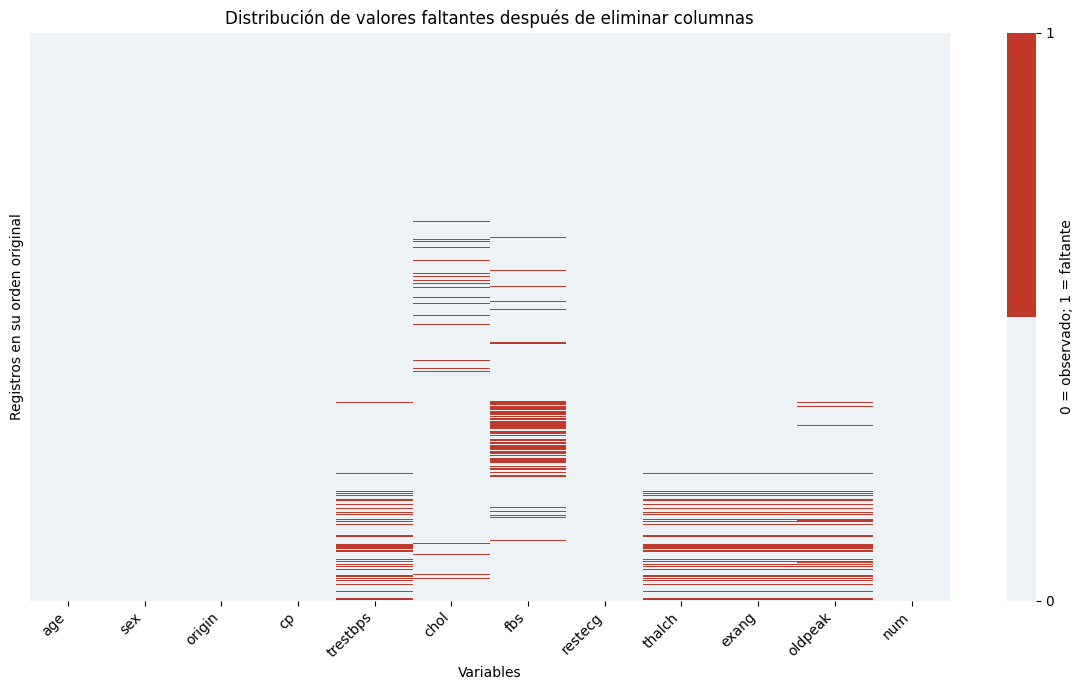

,Faltantes totales,Faltantes junto con thalch
trestbps,59,55
chol,30,3
fbs,89,0
thalch,55,55
exang,55,55
oldpeak,62,54


In [16]:
# Calcular la cantidad y el porcentaje de faltantes por columna
tabla_faltantes = pd.DataFrame({
    "Faltantes": cardio_df.isna().sum(),
    "Porcentaje (%)": cardio_df.isna().mean() * 100
}).sort_values("Porcentaje (%)", ascending=False)

display(tabla_faltantes.round(2))

# Identificar las columnas que superan el 30% de faltantes
columnas_eliminar = tabla_faltantes.loc[
    tabla_faltantes["Porcentaje (%)"] > 30
].index

# Mostrar las columnas seleccionadas y eliminarlas del dataframe
display(tabla_faltantes.loc[columnas_eliminar].round(2))

cardio_df = cardio_df.drop(columns=columnas_eliminar)

# Comprobar las dimensiones después de eliminar columnas
display(
    pd.Series({
        "Registros restantes": cardio_df.shape[0],
        "Columnas restantes": cardio_df.shape[1]
    }).to_frame(name="Cantidad")
)

# Visualizar los faltantes en todas las columnas restantes
plt.figure(figsize=(12, 7))

sns.heatmap(
    cardio_df.isna(),
    cmap=["#edf2f7", "#c0392b"],
    vmin=0,
    vmax=1,
    yticklabels=False,
    cbar_kws={
        "ticks": [0, 1],
        "label": "0 = observado; 1 = faltante"
    }
)

plt.title("Distribución de valores faltantes después de eliminar columnas")
plt.xlabel("Variables")
plt.ylabel("Registros en su orden original")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Cuantificar la concurrencia usando thalch como referencia
faltantes_thalch = cardio_df["thalch"].isna()

tabla_concurrencia = pd.DataFrame({
    "Faltantes totales": cardio_df.isna().sum(),
    "Faltantes junto con thalch":
        cardio_df.loc[faltantes_thalch].isna().sum()
})

# Mostrar únicamente las variables que tienen faltantes
display(
    tabla_concurrencia.loc[
        tabla_concurrencia["Faltantes totales"] > 0
    ]
)

# Variables con patrones similares identificadas para el ejercicio 6
variables_patron_similar = ["thalch", "exang", "trestbps", "oldpeak"]

**Resultados del ejercicio 4**

Se calculó la cantidad y el porcentaje de valores faltantes de cada columna utilizando como denominador los 918 registros. Las variables `ca`, `thal` y `slope` presentaron porcentajes de 66.34%, 52.72% y 33.55%, respectivamente. Se eliminaron estas tres columnas porque superan el umbral del 30% establecido en la actividad. El dataframe conservó los 918 registros y quedó con 12 columnas.

El mapa de calor y el conteo de coincidencias permitieron identificar un patrón de faltantes compartido entre `thalch`, `exang`, `trestbps` y `oldpeak`. Las variables `thalch` y `exang` tienen un patrón idéntico: ambas están ausentes en los mismos 55 registros. En esos registros también falta `trestbps` en 55 casos y `oldpeak` en 54. Por tanto, estas dos últimas variables presentan patrones similares, aunque no idénticos.

La concurrencia tiene una explicación clínica plausible. De acuerdo con el diccionario de UCI, `thalch` representa la frecuencia cardíaca máxima alcanzada, `exang` la angina inducida por ejercicio y `oldpeak` el cambio del segmento ST inducido por ejercicio respecto al reposo. Estas variables están vinculadas con la evaluación de la respuesta al esfuerzo. La American Heart Association señala que durante una prueba de esfuerzo se monitorizan la frecuencia cardíaca, la presión arterial y el electrocardiograma. [UCI Heart Disease](https://archive.ics.uci.edu/dataset/45/heart+disease); [American Heart Association, *Exercise Stress Test*](https://www.heart.org/en/health-topics/heart-attack/diagnosing-a-heart-attack/exercise-stress-test).

Una evaluación no realizada, incompleta o con resultados sin registrar podría explicar la ausencia conjunta de varias mediciones. Esta interpretación es una hipótesis: el archivo no documenta la causa de los faltantes. Además, `trestbps` corresponde a una medición en reposo, por lo que su concurrencia también podría relacionarse con la captura o integración de los datos.

Se identificaron `thalch`, `exang`, `trestbps` y `oldpeak` como el grupo de variables con patrones similares para la imputación del ejercicio 6. Esta selección se apoya en la coincidencia observada entre registros y no implica que todas compartan necesariamente la misma causa de ausencia.

5. Si centramos el análisis en una de las variables identificadas en el ejercicio anterior, se puede suponer que los hallazgos obtenidos podrían ser aplicables a las demás variables que presentan un patrón similar.

* ¿Tendrán los valores faltantes de `thalch` relación con alguna otra variable? Analízalo considerando las siguientes columnas:
  *   Numéricas: `age`, `chol`
  *   Categóricas: `restecg`, `cp`

Para ello deberás dividir cada columna en dos grupos: con / sin faltantes en `thalch` y utilizar métodos gráficos y pruebas de hipótesis para ver si hay diferencias significativas.
* Incluye las conclusiones del análisis con los resultados obtenidos.
* Justifica si el mecanismo de faltantes de `thalch` es MCAR (*Missing Completely at Random*) o MAR (*Missing at Random*).

**NOTA**. Puedes reutilizar las funciones `Diagnose_MV_Numerical` y `Diagnose_MV_Categorical` definidas en Hands-On-Prep_Missing_Values.zip. Revisa nuevamente cómo utilizarlas.

,Número de registros
Con faltantes en thalch,55
Sin faltantes en thalch,863


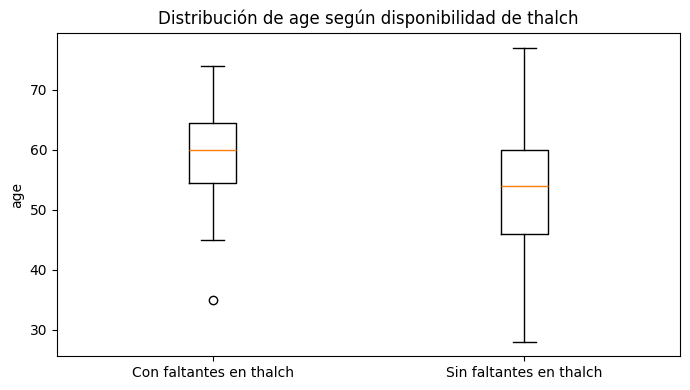

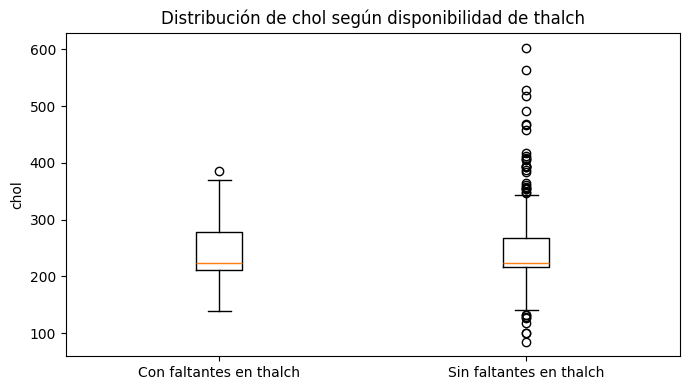

,n con faltantes,n sin faltantes,Media con faltantes,Media sin faltantes,Mediana con faltantes,Mediana sin faltantes,t de Welch,p,p < 0.05
Variable,,,,,,,,,
age,55,863,59.42,53.16,60.00,54.00,5.640,4.116e-07,True
chol,52,836,239.58,242.35,223.00,224.00,-0.373,7.105e-01,False


restecg,lv hypertrophy,normal,st-t abnormality
Grupo,,,
Con faltantes en thalch,7,19,29
Sin faltantes en thalch,181,532,150


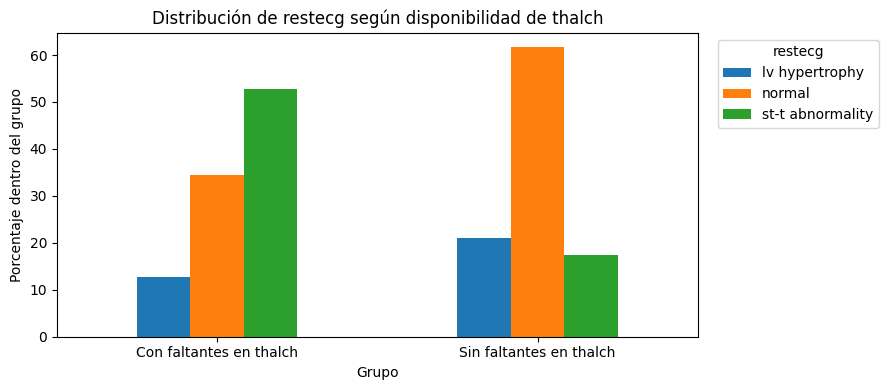

cp,asymptomatic,atypical angina,non-anginal,typical angina
Grupo,,,,
Con faltantes en thalch,26,7,18,4
Sin faltantes en thalch,469,167,186,41


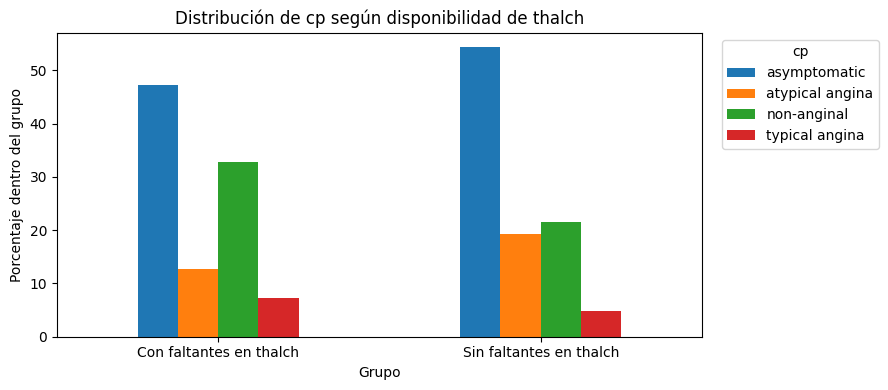

,Método,Chi-cuadrada,Mínima frecuencia esperada,p,p < 0.05
Variable,,,,,
restecg,Chi-cuadrada: aproximación,41.172,10.724,1.147e-09,True
cp,Chi-cuadrada: Monte Carlo,5.253,2.696,1.494e-01,False


In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind, chi2_contingency, MonteCarloMethod


# ============================================================
# 1. Separar los registros según los faltantes de thalch
# ============================================================

alpha = 0.05

faltantes_thalch = cardio_df["thalch"].isna()

resumen_grupos = pd.Series({
    "Con faltantes en thalch": int(faltantes_thalch.sum()),
    "Sin faltantes en thalch": int((~faltantes_thalch).sum())
}).to_frame(name="Número de registros")

display(resumen_grupos)


# ============================================================
# 2. Variables numéricas: age y chol
#    Gráficas y pruebas t de Welch
# ============================================================

resultados_numericos = []

for variable in ["age", "chol"]:

    # Utilizar los valores observados de cada variable
    grupo_con = cardio_df.loc[faltantes_thalch, variable].dropna()
    grupo_sin = cardio_df.loc[~faltantes_thalch, variable].dropna()

    # Boxplot para comparar ambos grupos
    fig, ax = plt.subplots(figsize=(7, 4))

    ax.boxplot([grupo_con, grupo_sin])
    ax.set_xticks([1, 2])
    ax.set_xticklabels([
        "Con faltantes en thalch",
        "Sin faltantes en thalch"
    ])
    ax.set_ylabel(variable)
    ax.set_title(f"Distribución de {variable} según disponibilidad de thalch")

    plt.tight_layout()
    plt.show()

    # H0: las medias de los dos grupos son iguales
    # H1: las medias de los dos grupos son diferentes
    prueba = ttest_ind(
        grupo_con,
        grupo_sin,
        equal_var=False,
        alternative="two-sided"
    )

    resultados_numericos.append({
        "Variable": variable,
        "n con faltantes": len(grupo_con),
        "n sin faltantes": len(grupo_sin),
        "Media con faltantes": grupo_con.mean(),
        "Media sin faltantes": grupo_sin.mean(),
        "Mediana con faltantes": grupo_con.median(),
        "Mediana sin faltantes": grupo_sin.median(),
        "t de Welch": prueba.statistic,
        "p": prueba.pvalue,
        "p < 0.05": prueba.pvalue < alpha
    })

tabla_numericas = pd.DataFrame(
    resultados_numericos
).set_index("Variable")

display(
    tabla_numericas.style.format({
        "Media con faltantes": "{:.2f}",
        "Media sin faltantes": "{:.2f}",
        "Mediana con faltantes": "{:.2f}",
        "Mediana sin faltantes": "{:.2f}",
        "t de Welch": "{:.3f}",
        "p": "{:.3e}"
    })
)


# ============================================================
# 3. Variables categóricas: restecg y cp
#    Tablas, gráficas y pruebas de independencia
# ============================================================

resultados_categoricos = []

for variable in ["restecg", "cp"]:

    # Construir la tabla de contingencia con conteos
    tabla = pd.crosstab(
        faltantes_thalch,
        cardio_df[variable]
    ).reindex(index=[True, False])

    tabla.index = [
        "Con faltantes en thalch",
        "Sin faltantes en thalch"
    ]
    tabla.index.name = "Grupo"

    display(tabla)

    # Calcular porcentajes dentro de cada grupo
    porcentajes = tabla.div(tabla.sum(axis=1), axis=0) * 100

    # Comparar las proporciones mediante una gráfica de barras
    ax = porcentajes.plot(
        kind="bar",
        figsize=(9, 4),
        rot=0
    )

    ax.set_title(
        f"Distribución de {variable} según disponibilidad de thalch"
    )
    ax.set_xlabel("Grupo")
    ax.set_ylabel("Porcentaje dentro del grupo")
    ax.legend(
        title=variable,
        bbox_to_anchor=(1.02, 1),
        loc="upper left"
    )

    plt.tight_layout()
    plt.show()

    # H0: la categoría es independiente de la ausencia de thalch
    # H1: existe asociación entre ambas
    prueba = chi2_contingency(
        tabla,
        correction=False
    )

    estadistico = prueba.statistic
    p_valor = prueba.pvalue
    esperadas = prueba.expected_freq
    metodo = "Chi-cuadrada: aproximación"

    # Utilizar Monte Carlo si hay frecuencias esperadas menores que 5
    if (esperadas < 5).any():

        prueba_mc = chi2_contingency(
            tabla,
            correction=False,
            method=MonteCarloMethod(
                n_resamples=19999,
                rng=np.random.default_rng(2026)
            )
        )

        p_valor = prueba_mc.pvalue
        metodo = "Chi-cuadrada: Monte Carlo"

    resultados_categoricos.append({
        "Variable": variable,
        "Método": metodo,
        "Chi-cuadrada": estadistico,
        "Mínima frecuencia esperada": esperadas.min(),
        "p": p_valor,
        "p < 0.05": p_valor < alpha
    })

tabla_categoricas = pd.DataFrame(
    resultados_categoricos
).set_index("Variable")

display(
    tabla_categoricas.style.format({
        "Chi-cuadrada": "{:.3f}",
        "Mínima frecuencia esperada": "{:.3f}",
        "p": "{:.3e}"
    })
)

**Resultados del ejercicio 5**

Se analizó si la ausencia de valores en `thalch` estaba relacionada con las variables numéricas `age` y `chol`, y con las variables categóricas `restecg` y `cp`. Los registros se dividieron en dos grupos: **55 con `thalch` faltante y 863 con `thalch` observado**.

Se utilizaron boxplots para comparar las variables numéricas y gráficas de proporciones para las categóricas. Estas últimas permiten comparar la composición de los grupos considerando que sus tamaños son diferentes. Se estableció un nivel de significancia de **α = 0.05** y se realizaron cuatro contrastes exploratorios, sin ajuste por comparaciones múltiples.

**Comparación de las variables numéricas**

Para cada variable numérica, la hipótesis nula planteó que las medias de ambos grupos eran iguales, mientras que la alternativa planteó una diferencia. Se utilizó la prueba t de Welch, que permite comparar medias sin asumir igualdad de varianzas. [Documentación de SciPy: `ttest_ind`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html).

En `age`, el grupo con `thalch` faltante presentó una edad media de **59.42 años**, frente a **53.16 años** en el grupo con `thalch` observado. Las medianas fueron de 60 y 54 años, respectivamente. La diferencia de medias fue de aproximadamente **6.26 años**. La prueba obtuvo **t = 5.640** y **p ≈ 4.12 × 10⁻⁷**, por lo que se rechazó la hipótesis de igualdad de medias. Estos resultados aportan evidencia de una relación entre la edad y la ausencia de `thalch`.

En `chol`, las medias fueron de **239.58 mg/dl** en el grupo con `thalch` faltante y **242.35 mg/dl** en el grupo con `thalch` observado. Para esta comparación se utilizaron **52 y 836 observaciones**, respectivamente, porque se excluyeron los valores faltantes propios de colesterol. La prueba obtuvo **t = −0.373** y **p ≈ 0.7105**. No se rechazó la hipótesis nula: no hay evidencia suficiente para afirmar que las medias de colesterol difieren entre los grupos. Esto no demuestra que sus distribuciones sean idénticas ni descarta otras formas de asociación.

**Comparación de las variables categóricas**

Para cada variable categórica, la hipótesis nula estableció independencia respecto a la ausencia de `thalch`; la alternativa planteó una asociación.

En `restecg`, la prueba de chi-cuadrada obtuvo **χ² = 41.172** y **p ≈ 1.15 × 10⁻⁹**. Se rechazó la hipótesis de independencia. La categoría `st-t abnormality` representó el **52.73%** de los registros con `thalch` faltante, frente al **17.38%** de aquellos con `thalch` observado. Por tanto, existe evidencia de asociación entre el resultado del electrocardiograma en reposo y la disponibilidad de `thalch`.

En `cp`, el estadístico fue **χ² = 5.253**. La tabla presentó una frecuencia esperada mínima de aproximadamente **2.70**, por lo que se calculó el valor p mediante Monte Carlo para evitar depender de la aproximación asintótica con frecuencias pequeñas. El valor p obtenido se situó alrededor de **0.15**, por encima de 0.05. No se rechazó la hipótesis de independencia: no hay evidencia suficiente para afirmar una asociación entre el tipo de dolor torácico y la ausencia de `thalch`. [Documentación de SciPy: `chi2_contingency`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.chi2_contingency.html).

| Variable | Prueba utilizada | Valor p aproximado | Resultado con α = 0.05 |
|---|---|---:|---|
| `age` | t de Welch | 4.12 × 10⁻⁷ | Diferencia significativa entre las medias. |
| `chol` | t de Welch | 0.7105 | No se encontró diferencia significativa entre las medias. |
| `restecg` | Chi-cuadrada | 1.15 × 10⁻⁹ | Asociación significativa con la ausencia de `thalch`. |
| `cp` | Chi-cuadrada con Monte Carlo | 0.15 | No se encontró asociación significativa. |

**Justificación del mecanismo de faltantes**

El mecanismo **MCAR** supone que la ausencia es independiente tanto de la información observada como de los valores no observados. Las diferencias identificadas en edad y la asociación con `restecg` aportan evidencia contra este supuesto para `thalch`.

Entre las dos alternativas solicitadas, **MAR es un supuesto de trabajo más defendible que MCAR**, porque la ausencia de `thalch` se relaciona con variables observadas. Sin embargo, adoptar MAR requiere asumir que, una vez considerada la información observada relevante, la probabilidad de ausencia ya no depende del valor no registrado de `thalch`.

Los resultados no demuestran esa condición ni permiten descartar **MNAR**, donde la ausencia podría depender del propio valor no observado, incluso después de considerar otras variables. No hay evidencia suficiente para determinarlo únicamente con estos contrastes. Esta distinción es importante porque encontrar asociaciones con variables observadas permite cuestionar MCAR, pero no confirmar automáticamente MAR. [Sterne et al., 2009, *The BMJ*](https://www.bmj.com/content/338/bmj.b2393).

En consecuencia, se considera MAR como una hipótesis de trabajo para continuar la actividad, reconociendo su incertidumbre. Las asociaciones encontradas no establecen causalidad ni garantizan que las demás variables con patrones de faltantes similares compartan exactamente el mismo mecanismo.

6. La imputación de una variable con valores faltantes puede realizarse por grupos o segmentos relevantes. Esto significa que, en lugar de utilizar una estadística global de toda la columna, se calcula la estadística correspondiente dentro de cada grupo definido por otra variable, haciendo:

> `df['var_with_missing'] = df.groupby('related_var')['var_with_missing'].transform(lambda x: x.fillna(x.median()))`

* Utiliza la variable `restecg` para separar los grupos e imputar `thalch` y todas las variables con patrón de faltantes similar (identificadas en el ejercicio 4) Asegúrate de cambiar la función de agregado si hay variables no numéricas.
* Vuelve a generar el mapa de calor para verificar que los valores faltantes en estas variables hayan sido imputados.

,Faltantes antes,Valores imputados,Faltantes después
thalch,55,55,0
trestbps,59,59,0
oldpeak,62,62,0
exang,55,55,0


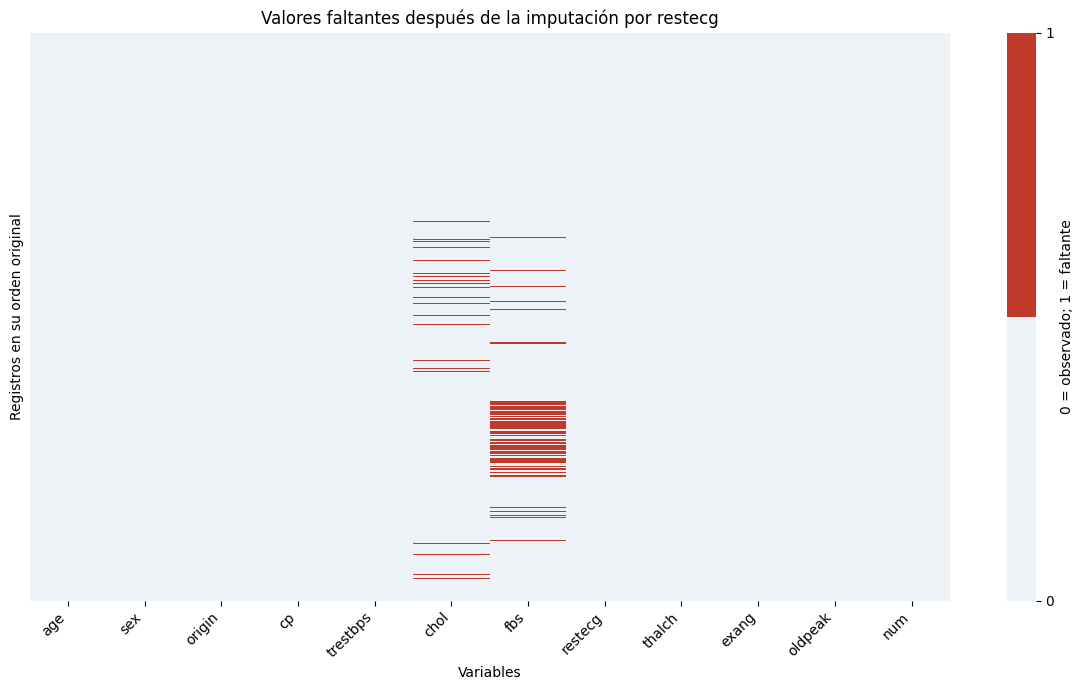

,Faltantes pendientes
chol,30
fbs,89


,Cantidad
Número de registros,918
Número de columnas,12


In [18]:
# ============================================================
# 1. Registrar los faltantes antes de la imputación
# ============================================================

variables_imputar = ["thalch", "trestbps", "oldpeak", "exang"]

faltantes_antes = cardio_df[variables_imputar].isna().sum()


# ============================================================
# 2. Imputar las variables numéricas con la mediana por restecg
# ============================================================

for variable in ["thalch", "trestbps", "oldpeak"]:

    # Identificar las posiciones que necesitan imputación
    faltantes = cardio_df[variable].isna()

    # Obtener para cada registro la mediana de su grupo
    medianas_por_grupo = (
        cardio_df.groupby("restecg", observed=True)[variable]
        .transform("median")
    )

    # Sustituir únicamente los valores faltantes
    cardio_df.loc[faltantes, variable] = (
        medianas_por_grupo.loc[faltantes]
    )


# ============================================================
# 3. Imputar exang con la moda por restecg
# ============================================================

faltantes_exang = cardio_df["exang"].isna()

modas_por_grupo = (
    cardio_df.groupby("restecg", observed=True)["exang"]
    .transform(lambda grupo: grupo.mode().iloc[0])
)

cardio_df.loc[faltantes_exang, "exang"] = (
    modas_por_grupo.loc[faltantes_exang]
)


# ============================================================
# 4. Comparar los faltantes antes y después
# ============================================================

faltantes_despues = cardio_df[variables_imputar].isna().sum()

resumen_imputacion = pd.DataFrame({
    "Faltantes antes": faltantes_antes,
    "Valores imputados": faltantes_antes - faltantes_despues,
    "Faltantes después": faltantes_despues
})

display(resumen_imputacion)


# ============================================================
# 5. Generar nuevamente el mapa de calor
# ============================================================

plt.figure(figsize=(12, 7))

sns.heatmap(
    cardio_df.isna(),
    cmap=["#edf2f7", "#c0392b"],
    vmin=0,
    vmax=1,
    yticklabels=False,
    cbar_kws={
        "ticks": [0, 1],
        "label": "0 = observado; 1 = faltante"
    }
)

plt.title("Valores faltantes después de la imputación por restecg")
plt.xlabel("Variables")
plt.ylabel("Registros en su orden original")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


# ============================================================
# 6. Identificar los faltantes pendientes para el ejercicio 7
# ============================================================

faltantes_pendientes = cardio_df.isna().sum()

display(
    faltantes_pendientes.loc[faltantes_pendientes > 0]
    .to_frame(name="Faltantes pendientes")
)

# Comprobar las dimensiones del dataframe
display(
    pd.Series({
        "Número de registros": cardio_df.shape[0],
        "Número de columnas": cardio_df.shape[1]
    }).to_frame(name="Cantidad")
)

**Resultados del ejercicio 6**

Se imputaron los valores faltantes de `thalch`, `trestbps`, `oldpeak` y `exang`, utilizando `restecg` como variable de agrupación. Estas variables se seleccionaron por los patrones de ausencia similares identificados en el ejercicio 4.

Para `thalch`, `trestbps` y `oldpeak` se utilizó la mediana de los valores observados dentro de cada grupo. Se eligió esta medida por su menor sensibilidad a los valores extremos. Para `exang` se utilizó la moda, ya que es una variable categórica binaria.

Las medianas de `thalch` fueron 146 para `lv hypertrophy`, 140 para `normal` y 129 para `st-t abnormality`. En `trestbps`, la mediana fue 130 en los tres grupos. Para `oldpeak`, las medianas fueron 0.8, 0.2 y 0.9, respectivamente. La moda de `exang` fue `False` en todos los grupos. Aunque algunas estadísticas coincidieron entre grupos, se calcularon de manera independiente para cada uno.

Se completaron 55 valores de `thalch`, 59 de `trestbps`, 62 de `oldpeak` y 55 de `exang`. La tabla de verificación y el nuevo mapa de calor confirmaron que estas cuatro variables quedaron sin valores faltantes. El procedimiento conservó los valores originalmente observados, así como los 918 registros y las 12 columnas del dataframe.

Después de esta etapa permanecieron 30 faltantes en `chol` y 89 en `fbs`, que se atenderán en el ejercicio 7.

La imputación permite continuar el análisis con datos completos en las variables seleccionadas, pero los valores incorporados son estimaciones y no mediciones recuperadas. Además, la imputación mediante una única estadística por grupo puede reducir la variabilidad y aumentar la frecuencia de ciertos valores. Por tanto, completar los faltantes no garantiza que se haya eliminado el sesgo asociado con su ausencia.

7. Para las variables que aún presentan valores faltantes, realiza la imputación utilizando estadísticas generales calculadas sobre toda la columna, sin segmentar por grupos. Esta vez utiliza la clase `SimpleImputer` de sklearn
* Justifica la estrategia (*mean, median, most_frequent*) que emplees en cada caso.


In [19]:
from sklearn.impute import SimpleImputer


# ============================================================
# 1. Registrar los faltantes antes de la imputación
# ============================================================

variables_pendientes = ["chol", "fbs"]

faltantes_antes = cardio_df[variables_pendientes].isna().sum()


# ============================================================
# 2. Imputar chol con la mediana global
# ============================================================

imputador_chol = SimpleImputer(strategy="median")

cardio_df["chol"] = imputador_chol.fit_transform(
    cardio_df[["chol"]]
).ravel()


# ============================================================
# 3. Imputar fbs con la moda global
# ============================================================

imputador_fbs = SimpleImputer(strategy="most_frequent")

valores_fbs = imputador_fbs.fit_transform(
    cardio_df[["fbs"]].astype(object)
)

# Conservar los valores booleanos True y False
cardio_df["fbs"] = valores_fbs.ravel().astype(bool)


# ============================================================
# 4. Mostrar las estrategias y los resultados
# ============================================================

faltantes_despues = cardio_df[variables_pendientes].isna().sum()

resumen_imputacion_global = pd.DataFrame({
    "Estrategia": ["median", "most_frequent"],
    "Valor de imputación": [
        imputador_chol.statistics_[0],
        bool(imputador_fbs.statistics_[0])
    ],
    "Faltantes antes": faltantes_antes,
    "Valores imputados": faltantes_antes - faltantes_despues,
    "Faltantes después": faltantes_despues
}, index=variables_pendientes)

display(resumen_imputacion_global)


# ============================================================
# 5. Comprobar los faltantes de todas las columnas
# ============================================================

display(
    cardio_df.isna().sum().to_frame(name="Faltantes finales")
)

display(
    pd.Series({
        "Número de registros": cardio_df.shape[0],
        "Número de columnas": cardio_df.shape[1],
        "Total de valores faltantes":
            int(cardio_df.isna().sum().sum())
    }).to_frame(name="Cantidad")
)

,Estrategia,Valor de imputación,Faltantes antes,Valores imputados,Faltantes después
chol,median,223.0,30,30,0
fbs,most_frequent,False,89,89,0


,Faltantes finales
age,0
sex,0
origin,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalch,0
exang,0


,Cantidad
Número de registros,918
Número de columnas,12
Total de valores faltantes,0


**Resultados del ejercicio 7**

Después de la imputación por grupos del ejercicio anterior, permanecieron valores faltantes en `chol` y `fbs`. Se utilizó la clase `SimpleImputer` de scikit-learn para completarlos con estadísticas globales, calculadas sobre los valores observados de cada columna.

Para `chol` se seleccionó la estrategia `median`. En el análisis descriptivo, esta variable presentó asimetría positiva, con una media de aproximadamente 242.19 mg/dl y una mediana de 223 mg/dl. Se eligió la mediana por su menor sensibilidad a los valores extremos. Los 30 valores faltantes se sustituyeron por **223 mg/dl**.

Para `fbs` se utilizó la estrategia `most_frequent`, porque es una variable categórica binaria que indica si la glucosa en ayunas supera los 120 mg/dl. La categoría más frecuente entre los valores observados fue `False`, con 691 registros, frente a 138 con `True`. Por ello, los 89 valores faltantes se sustituyeron por **`False`**. Se conservaron los valores booleanos de la variable.

La verificación posterior mostró que todas las columnas quedaron sin valores faltantes. El dataframe conservó sus **918 registros y 12 columnas**, con `id` como índice.

Estas imputaciones permiten continuar con el análisis de valores atípicos, pero los valores incorporados son estimaciones. La imputación con la mediana puede reducir la variabilidad de `chol`, mientras que la imputación con la moda aumenta la proporción de la categoría predominante en `fbs`. Por tanto, la ausencia de faltantes no garantiza por sí sola que los datos estén libres de sesgos o de otros problemas de calidad.

8. Dibuja boxplots de todas las variables numéricas.
* Obtén los valores atípicos mediante el método gráfico, a partir del objeto devuelto por el boxplot.

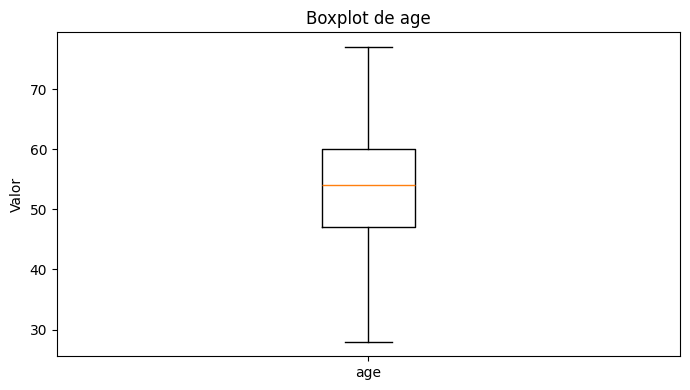

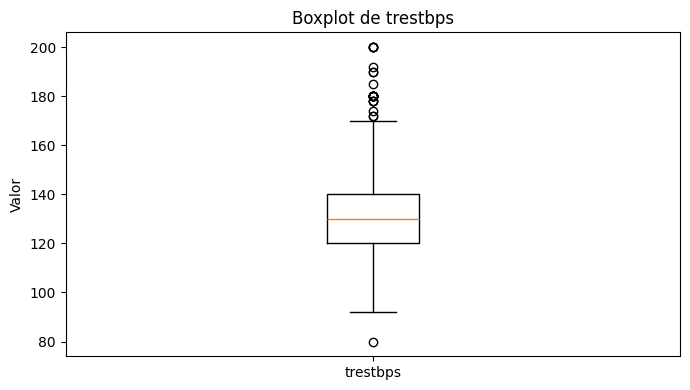

,Frecuencia
Valores atípicos de trestbps,
80.0,1
172.0,2
174.0,1
178.0,3
180.0,12
185.0,1
190.0,2
192.0,1
200.0,4


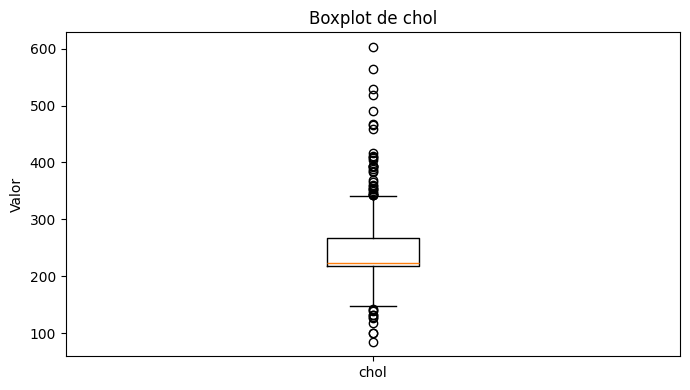

,Frecuencia
Valores atípicos de chol,
85.0,1
100.0,2
117.0,1
126.0,1
129.0,1
131.0,1
132.0,1
139.0,1
141.0,1


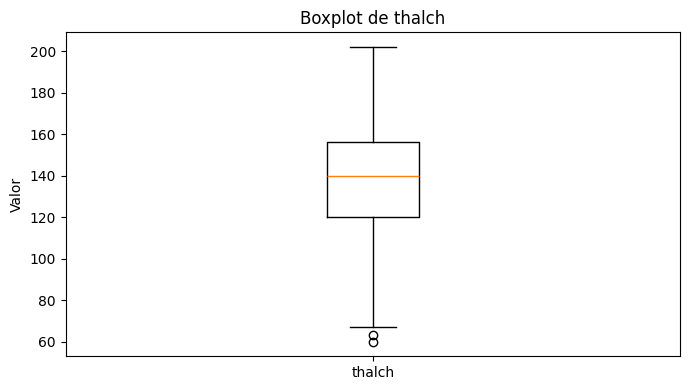

,Frecuencia
Valores atípicos de thalch,
60.0,1
63.0,1


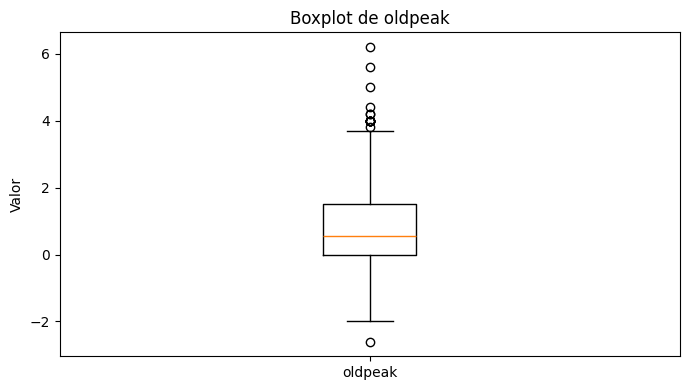

,Frecuencia
Valores atípicos de oldpeak,
-2.6,1
3.8,1
4.0,8
4.2,2
4.4,1
5.0,1
5.6,1
6.2,1


,Observaciones atípicas,Valores atípicos distintos
Variable,,
age,0,0
trestbps,27,9
chol,44,40
thalch,2,2
oldpeak,16,8


In [20]:
# ============================================================
# 1. Identificar las variables numéricas del dataframe actual
# ============================================================

columnas_numericas = cardio_df.select_dtypes(
    include="number"
).columns

# Guardar los valores atípicos para utilizarlos en el ejercicio 9
atipicos_boxplot = {}

# Guardar los conteos para construir una tabla de resumen
resumen_atipicos = []


# ============================================================
# 2. Dibujar los boxplots y extraer los valores atípicos
# ============================================================

for variable in columnas_numericas:

    fig, ax = plt.subplots(figsize=(7, 4))

    # Guardar el objeto devuelto por el boxplot
    objeto_boxplot = ax.boxplot(
        cardio_df[variable],
        whis=1.5,
        showfliers=True
    )

    ax.set_xticks([1])
    ax.set_xticklabels([variable])
    ax.set_ylabel("Valor")
    ax.set_title(f"Boxplot de {variable}")

    plt.tight_layout()
    plt.show()

    # Extraer los valores de los puntos atípicos del gráfico
    valores_atipicos = np.sort(
        objeto_boxplot["fliers"][0].get_ydata()
    )

    # Conservar todos los valores, incluyendo sus repeticiones
    atipicos_boxplot[variable] = valores_atipicos

    resumen_atipicos.append({
        "Variable": variable,
        "Observaciones atípicas": len(valores_atipicos),
        "Valores atípicos distintos": len(np.unique(valores_atipicos))
    })

    # Mostrar los valores atípicos y cuántas veces aparece cada uno
    if len(valores_atipicos) > 0:
        tabla_valores_atipicos = (
            pd.Series(valores_atipicos)
            .value_counts()
            .sort_index()
            .rename_axis(f"Valores atípicos de {variable}")
            .to_frame(name="Frecuencia")
        )

        display(tabla_valores_atipicos)


# ============================================================
# 3. Mostrar el resumen de todas las variables numéricas
# ============================================================

tabla_resumen_atipicos = pd.DataFrame(
    resumen_atipicos
).set_index("Variable")

display(tabla_resumen_atipicos)

**Resultados del ejercicio 8**

Se dibujaron boxplots de las cinco variables numéricas del dataframe: `age`, `trestbps`, `chol`, `thalch` y `oldpeak`. Se utilizó el criterio de Tukey, con bigotes definidos mediante 1.5 veces el rango intercuartílico.

Los valores atípicos se recuperaron directamente del componente `fliers` del objeto devuelto por cada boxplot. Como los gráficos tienen orientación vertical, se extrajeron sus coordenadas mediante `get_ydata()`. Se conservaron las repeticiones para contar las observaciones señaladas, además de identificar los valores distintos.

| Variable | Observaciones atípicas | Valores atípicos distintos |
|---|---:|---:|
| `age` | 0 | 0 |
| `trestbps` | 27 | 9 |
| `chol` | 44 | 40 |
| `thalch` | 2 | 2 |
| `oldpeak` | 16 | 8 |

El colesterol presentó el mayor número de observaciones atípicas, con 44, seguido de la presión arterial en reposo, con 27. En `oldpeak` se identificaron 16 y en `thalch` dos, correspondientes a los valores 60 y 63. En `age` no se identificaron observaciones fuera de los límites del boxplot; esto no implica que su distribución sea normal.

Para `trestbps`, los valores señalados fueron 80, 172, 174, 178, 180, 185, 190, 192 y 200. Algunos aparecen en varios registros, por lo que los nueve valores distintos corresponden a 27 observaciones.

Los conteos se interpretan por variable: un mismo registro puede presentar valores atípicos en más de una columna. Además, ser atípico bajo este criterio estadístico no demuestra que un dato sea incorrecto ni que deba eliminarse automáticamente. En esta etapa se conservaron todos los registros y se guardaron los valores extraídos para la comparación del ejercicio siguiente.

9. Para la variable `trestbps`, calcula los valores atípicos utilizando el método del rango intercuartílico (IQR).
* Para ello obtén los cuartiles necesarios y determina los límites superior e inferior para filtrar los valores que se encuentren fuera de ese rango.
* Verifica si los resultados coinciden con los obtenidos en el ejercicio anterior.

In [21]:
# ============================================================
# 1. Calcular los cuartiles y el rango intercuartílico
# ============================================================

q1_trestbps = cardio_df["trestbps"].quantile(0.25)
q3_trestbps = cardio_df["trestbps"].quantile(0.75)

iqr_trestbps = q3_trestbps - q1_trestbps


# ============================================================
# 2. Calcular los límites para identificar valores atípicos
# ============================================================

limite_inferior_trestbps = q1_trestbps - 1.5 * iqr_trestbps
limite_superior_trestbps = q3_trestbps + 1.5 * iqr_trestbps

display(
    pd.Series({
        "Primer cuartil (Q1)": q1_trestbps,
        "Tercer cuartil (Q3)": q3_trestbps,
        "Rango intercuartílico (IQR)": iqr_trestbps,
        "Límite inferior": limite_inferior_trestbps,
        "Límite superior": limite_superior_trestbps
    }).to_frame(name="Valor")
)


# ============================================================
# 3. Identificar y filtrar los valores fuera de los límites
# ============================================================

mascara_atipicos_trestbps = (
    (cardio_df["trestbps"] < limite_inferior_trestbps)
    | (cardio_df["trestbps"] > limite_superior_trestbps)
)

atipicos_trestbps_iqr = cardio_df.loc[
    mascara_atipicos_trestbps,
    "trestbps"
]

# Mostrar los valores atípicos y sus frecuencias
display(
    atipicos_trestbps_iqr
    .value_counts()
    .sort_index()
    .rename_axis("Valor atípico de trestbps")
    .to_frame(name="Frecuencia")
)


# ============================================================
# 4. Comparar con los valores extraídos del boxplot
# ============================================================

# Ordenar ambos conjuntos conservando todas las repeticiones
valores_iqr = np.sort(atipicos_trestbps_iqr.to_numpy())
valores_boxplot = np.sort(atipicos_boxplot["trestbps"])

coinciden_atipicos = np.array_equal(
    valores_iqr,
    valores_boxplot
)

display(
    pd.Series({
        "Observaciones atípicas por IQR": len(valores_iqr),
        "Observaciones atípicas por boxplot": len(valores_boxplot),
        "Coinciden los valores y sus repeticiones":
            bool(coinciden_atipicos)
    }).to_frame(name="Resultado")
)

,Valor
Primer cuartil (Q1),120.0
Tercer cuartil (Q3),140.0
Rango intercuartílico (IQR),20.0
Límite inferior,90.0
Límite superior,170.0


,Frecuencia
Valor atípico de trestbps,
80.0,1
172.0,2
174.0,1
178.0,3
180.0,12
185.0,1
190.0,2
192.0,1
200.0,4


,Resultado
Observaciones atípicas por IQR,27
Observaciones atípicas por boxplot,27
Coinciden los valores y sus repeticiones,True


**Resultados del ejercicio 9**

Se aplicó el método del rango intercuartílico a `trestbps`, utilizando los datos posteriores a las imputaciones de los ejercicios 6 y 7.

El primer cuartil fue de **120 mm Hg** y el tercer cuartil de **140 mm Hg**. Por tanto, el rango intercuartílico fue:

\[
IQR = 140-120 = 20\text{ mm Hg}
\]

Con el criterio de 1.5 veces el IQR, se obtuvieron los siguientes límites:

\[
Límite\ inferior = 120-1.5(20)=90\text{ mm Hg}
\]

\[
Límite\ superior = 140+1.5(20)=170\text{ mm Hg}
\]

Se identificaron como atípicos los registros con valores de `trestbps` menores que 90 o mayores que 170 mm Hg. Se encontraron **27 observaciones**, correspondientes a nueve valores distintos: 80, 172, 174, 178, 180, 185, 190, 192 y 200 mm Hg.

Los resultados se compararon con los valores extraídos del objeto del boxplot en el ejercicio 8. La comparación conservó las repeticiones y confirmó una coincidencia exacta en los valores y sus frecuencias.

Esta coincidencia es consistente con el uso del mismo criterio de 1.5 IQR en ambos procedimientos. Los límites calculados son umbrales estadísticos determinados por la distribución de este conjunto de datos; no representan límites clínicos de normalidad.

En este ejercicio se identificaron y almacenaron los registros señalados, conservando el dataframe completo para realizar la eliminación solicitada en el ejercicio 10.

10. Elimina los valores atípicos identificados de la variable `trestbps`.
* Dibuja el boxplot final para visualizar la distribución depurada.

,Cantidad
Registros antes,918
Registros eliminados,27
Registros después,891
Columnas restantes,12
Valores faltantes,0


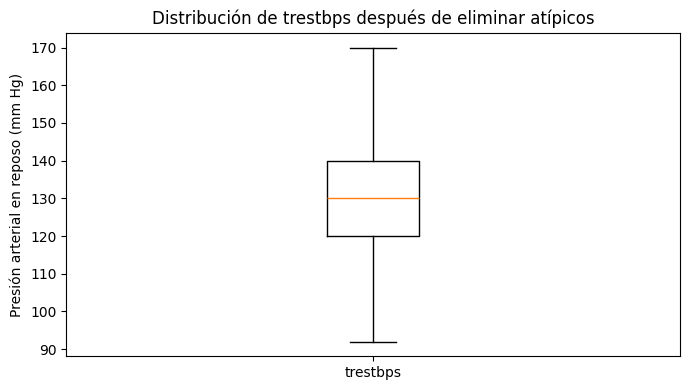

,Valor
Presión mínima (mm Hg),92.0
Presión máxima (mm Hg),170.0
Observaciones atípicas en el boxplot final,0.0


In [22]:
# ============================================================
# 1. Eliminar los registros identificados en el ejercicio 9
# ============================================================

registros_antes = len(cardio_df)

# Conservar las filas que no fueron señaladas como atípicas
cardio_df = cardio_df.loc[~mascara_atipicos_trestbps].copy()

registros_despues = len(cardio_df)
registros_eliminados = registros_antes - registros_despues

# Mostrar el resultado de la eliminación
display(
    pd.Series({
        "Registros antes": registros_antes,
        "Registros eliminados": registros_eliminados,
        "Registros después": registros_despues,
        "Columnas restantes": cardio_df.shape[1],
        "Valores faltantes":
            int(cardio_df.isna().sum().sum())
    }).to_frame(name="Cantidad")
)


# ============================================================
# 2. Dibujar el boxplot final de trestbps
# ============================================================

fig, ax = plt.subplots(figsize=(7, 4))

boxplot_final_trestbps = ax.boxplot(
    cardio_df["trestbps"],
    whis=1.5,
    showfliers=True
)

ax.set_xticks([1])
ax.set_xticklabels(["trestbps"])
ax.set_ylabel("Presión arterial en reposo (mm Hg)")
ax.set_title("Distribución de trestbps después de eliminar atípicos")

plt.tight_layout()
plt.show()


# ============================================================
# 3. Verificar la distribución final
# ============================================================

atipicos_finales_trestbps = (
    boxplot_final_trestbps["fliers"][0].get_ydata()
)

display(
    pd.Series({
        "Presión mínima (mm Hg)": cardio_df["trestbps"].min(),
        "Presión máxima (mm Hg)": cardio_df["trestbps"].max(),
        "Observaciones atípicas en el boxplot final":
            len(atipicos_finales_trestbps)
    }).to_frame(name="Valor")
)

**Resultados del ejercicio 10**

Se eliminaron los registros identificados como atípicos en `trestbps` mediante el criterio del rango intercuartílico del ejercicio 9. Los límites establecidos fueron de 90 y 170 mm Hg, por lo que se excluyeron las filas con presiones menores que 90 o mayores que 170 mm Hg.

Se eliminaron **27 registros**, equivalentes aproximadamente al **2.94%** de los 918 registros disponibles. El dataframe final quedó con **891 registros y 12 columnas**, conservando `id` como índice y sin valores faltantes.

El boxplot final mostró una presión arterial en reposo mínima de **92 mm Hg** y máxima de **170 mm Hg**. La extracción de los puntos del componente `fliers` confirmó que no quedaron observaciones atípicas en `trestbps` bajo el criterio de 1.5 IQR aplicado a la distribución final.

La eliminación se realizó conforme a la instrucción de la actividad y utilizando exclusivamente los atípicos identificados en `trestbps`. La clasificación estadística como atípico no demuestra que un valor sea un error de medición. Además, excluir registros extremos puede modificar la representación de los pacientes con presiones poco frecuentes, por lo que esta decisión debe tenerse en cuenta al interpretar análisis posteriores.

---

**Declaración de uso de IA**

Referencias de las herramientas utilizadas

Anthropic. (2026). Claude (Claude Sonnet 5.5) [Modelo de lenguaje grande], utilizado para depuración de código y como apoyo en la validación de pruebas en cada pregunta. https://claude.ai/


OpenAI. (2026). Codex, basado en GPT-6.1 [Asistente de inteligencia artificial], utilizado para depuración de código, orientación metodológica y apoyo en la interpretación resultados. https://chat.openai.com/

---